In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

import sys
import os
# This gets the absolute path to the 'EE675' folder
parent_folder = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add it to the system path if it's not already there
if parent_folder not in sys.path:
    sys.path.append(parent_folder)

from induced_reward import induced_reward
from induced_kernel import induced_kernel
from state_value_eval import state_value_eval
from kernel import kernel
from reward import reward
from sample_policy import sample_policy

In [2]:
%load_ext autoreload
%autoreload 2

In [ ]:
def run_evaluation():
    Ns = [4,6,8,10,12]
    state_values_initial = []
    run_times = []
    gamma = 0.99

    for N in Ns:
        print(f"Processing N = {N}...")
        start_time = time.time()
        
        # 1. Generate Environment Components
        Kernel = kernel(N) 
        reward_func = reward(N)
        policy = sample_policy(N)
        
        # 2. Induced Dynamics
        P_pi = induced_kernel(Kernel, policy)
        R_pi = induced_reward(reward_func, policy)
        
        # 3. Policy Evaluation (Recursive/Iterative)
        V = state_value_eval(policy, Kernel, reward_func, gamma)
        
        # 4. Extract Initial State Value
        initial_idx = (1-1)*N**3 + (1-1)*N**2 + (N-1)*N + (N-1)
        v_initial = V[initial_idx][0]
        
        end_time = time.time()
        
        state_values_initial.append(v_initial)
        run_times.append(end_time - start_time)
        print(f"Finished N={N} in {end_time - start_time:.2f}s")

    return Ns, state_values_initial, run_times

In [4]:
# Run the simulation
Ns, values, times = run_evaluation()

Processing N = 4...
Finished N=4 in 0.05s
Processing N = 6...
Finished N=6 in 0.17s
Processing N = 8...
Finished N=8 in 0.50s
Processing N = 10...
Finished N=10 in 1.40s
Processing N = 12...
Finished N=12 in 2.93s


In [5]:
def plot_results(Ns, values, times):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Graph 1: State Value vs N
    ax1.plot(Ns, values, marker='o', color='b', linestyle='-')
    ax1.set_title('Initial State Value $V((1,1),(N,N))$ vs N')
    ax1.set_xlabel('Grid Size (N)')
    ax1.set_ylabel('Expected Discounted Reward')
    ax1.grid(True, alpha=0.3)

    # Graph 2: Run Time vs N
    ax2.plot(Ns, times, marker='s', color='r', linestyle='--')
    ax2.set_title('Execution Time vs N')
    ax2.set_xlabel('Grid Size (N)')
    ax2.set_ylabel('Time (seconds)')
    ax2.set_yscale('log') # Log scale is better for N^4 complexity
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

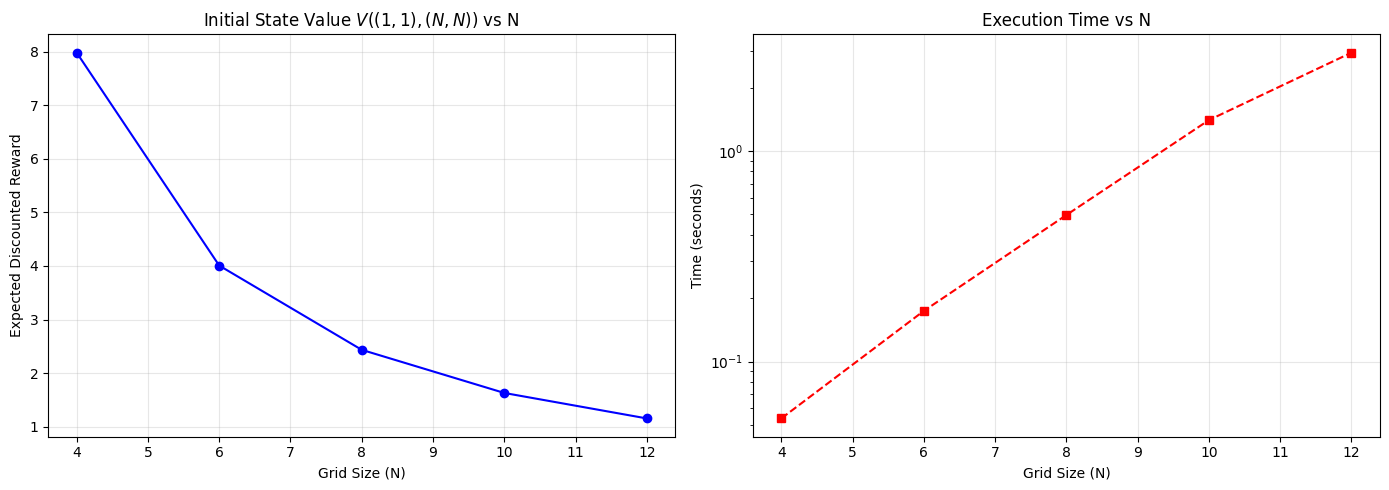

In [6]:
plot_results(Ns,values,times)